# 9. Falki

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-09.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})


## Programy z tekstu rozdziału

### Kod 9.1. Znikające momenty: całki i współczynniki sygnałów wielomianowych

In [2]:
import numpy as np
import pywt

# momenty falek obliczone numerycznie, wzór (9.3)
for nazwa in ("haar", "db2", "db3", "coif1"):
    w = pywt.Wavelet(nazwa)
    phi, psi, x = w.wavefun(level=12)
    dx = x[1] - x[0]
    momenty = [np.sum(x**n*psi)*dx for n in range(4)]
    print(f"{nazwa:6s}", " ".join(f"{m:8.4f}" for m in momenty),
          " deklarowane:", w.vanishing_moments_psi)

# współczynniki detali sygnałów wielomianowych
t = np.arange(64.0)
for stopien in (0, 1, 2):
    s = t**stopien
    wynik = []
    for nazwa in ("haar", "db2", "db3"):
        cD = pywt.dwt(s, nazwa, mode="zero")[1]
        wynik.append(np.abs(cD[4:-4]).max())       # bez brzegów
    print(f"stopień {stopien}:",
          " ".join(f"{v:10.2e}" for v in wynik))

haar     0.0000  -0.2500  -0.2501  -0.2188  deklarowane: 1
db2      0.0000   0.0000  -0.2165  -0.7868  deklarowane: 2
db3      0.0000   0.0000   0.0000  -0.2965  deklarowane: 3
coif1    0.0000   0.0000   0.2057   1.5760  deklarowane: 2
stopień 0:   0.00e+00   2.78e-17   2.08e-17
stopień 1:   7.07e-01   6.22e-15   6.00e-15
stopień 2:   7.71e+01   1.22e+00   2.27e-13


### Kod 9.2. Rodziny falek i ich własności w bibliotece PyWavelets

In [3]:
import pywt

for skrot, nazwa in zip(pywt.families(), pywt.families(short=False)):
    lista = pywt.wavelist(skrot)
    print(f"{skrot:5s} {nazwa:36s} {len(lista):2d}  {lista[0]}")

for nazwa in ("haar", "db4", "sym4", "coif2", "bior2.2", "dmey"):
    w = pywt.Wavelet(nazwa)
    print(f"{nazwa:8s} filtr {w.dec_len:2d}, "
          f"momenty psi/phi: {w.vanishing_moments_psi}/"
          f"{w.vanishing_moments_phi}, {w.symmetry}, "
          f"ortogonalna: {w.orthogonal}")

haar  Haar                                  1  haar
db    Daubechies                           38  db1
sym   Symlets                              19  sym2
coif  Coiflets                             17  coif1
bior  Biorthogonal                         15  bior1.1
rbio  Reverse biorthogonal                 15  rbio1.1
dmey  Discrete Meyer (FIR Approximation)    1  dmey
gaus  Gaussian                              8  gaus1
mexh  Mexican hat wavelet                   1  mexh
morl  Morlet wavelet                        1  morl
cgau  Complex Gaussian wavelets             8  cgau1
shan  Shannon wavelets                      1  shan
fbsp  Frequency B-Spline wavelets           1  fbsp
cmor  Complex Morlet wavelets               1  cmor
haar     filtr  2, momenty psi/phi: 1/0, asymmetric, ortogonalna: True
db4      filtr  8, momenty psi/phi: 4/0, asymmetric, ortogonalna: True
sym4     filtr  8, momenty psi/phi: 4/0, near symmetric, ortogonalna: True
coif2    filtr 12, momenty psi/phi: 4/3, near s

### Kod 9.3. Filtr db2 wyznaczony z warunków ortogonalności i znikających momentów

In [4]:
import numpy as np
import pywt
from scipy.optimize import fsolve

def warunki(h):
    n = np.arange(4)
    return [h.sum() - np.sqrt(2),            # unormowanie (6.9)
            h @ h - 1,                       # jednostkowa energia
            np.sum((-1)**n*h),               # pierwszy znikający moment
            np.sum((-1)**n*n*h)]             # drugi znikający moment

h = fsolve(warunki, [0.5, 0.8, 0.2, -0.1])
r3 = np.sqrt(3)
wzor = np.array([1 + r3, 3 + r3, 3 - r3, 1 - r3])/(4*np.sqrt(2))
print(h.round(6))
print(wzor.round(6))
print(np.allclose(h, pywt.Wavelet("db2").rec_lo))
print("ortogonalność do przesunięcia o 2:",
      round(h[0]*h[2] + h[1]*h[3], 12))

[ 0.482963  0.836516  0.224144 -0.12941 ]
[ 0.482963  0.836516  0.224144 -0.12941 ]
True
ortogonalność do przesunięcia o 2: 0.0


### Kod 9.4. Falka biortogonalna bior2.2: filtry, biortogonalność i odtworzenie sygnału

In [5]:
import numpy as np
import pywt

w = pywt.Wavelet("bior2.2")
print("analiza: ", (np.array(w.dec_lo)*np.sqrt(2)).round(4))
print("synteza: ", (np.array(w.rec_lo)*np.sqrt(2)).round(4))

# biortogonalność filtrów, wzór (9.13)
h_a, h_s = np.array(w.dec_lo)[::-1], np.array(w.rec_lo)
for k in (-1, 0, 1):
    przes = np.roll(np.concatenate([h_s, np.zeros(4)]), 2*k)
    print(k, round(float(np.concatenate([h_a, np.zeros(4)]) @ przes), 10))

rng = np.random.default_rng(8)
s = rng.normal(size=256)
cA, cD = pywt.dwt(s, w, mode="periodization")
print("odtworzenie:",
      np.allclose(pywt.idwt(cA, cD, w, mode="periodization"), s))
print("energia sygnału:", round(float(np.sum(s**2)), 2),
      " współczynników:", round(float(np.sum(cA**2) + np.sum(cD**2)), 2))

analiza:  [ 0.   -0.25  0.5   1.5   0.5  -0.25]
synteza:  [0.  0.5 1.  0.5 0.  0. ]
-1 0.0
0 1.0
1 0.0
odtworzenie: True
energia sygnału: 288.65  współczynników: 318.56


### Kod 9.5. Falka Meyera wyznaczona z definicji w dziedzinie częstotliwości

In [6]:
import numpy as np

def nu(x):
    x = np.clip(x, 0, 1)
    return x**4*(35 - 84*x + 70*x**2 - 20*x**3)

def widmo_phi(om):                          # wzór (9.15)
    a = np.abs(om)
    return np.where(a <= 2*np.pi/3, 1.0,
           np.where(a <= 4*np.pi/3,
                    np.cos(np.pi/2*nu(3*a/(2*np.pi) - 1)), 0.0))

def widmo_psi(om):                          # wzór (9.17)
    a = np.abs(om)
    modul = np.where((a >= 2*np.pi/3) & (a <= 4*np.pi/3),
                     np.sin(np.pi/2*nu(3*a/(2*np.pi) - 1)),
            np.where((a > 4*np.pi/3) & (a <= 8*np.pi/3),
                     np.cos(np.pi/2*nu(3*a/(4*np.pi) - 1)), 0.0))
    return np.exp(1j*om/2)*modul

N, dx = 2**12, 1/16                         # siatka w dziedzinie czasu
x = (np.arange(N) - N//2)*dx
om = 2*np.pi*np.fft.fftfreq(N, dx)

def odwrotna(widmo):                        # całka (4.17) przez FFT
    return np.fft.fftshift(np.fft.ifft(widmo)).real/dx

phi, psi = odwrotna(widmo_phi(om)), odwrotna(widmo_psi(om))
print("całka phi:", round(np.sum(phi)*dx, 6),
      " całka psi:", round(np.sum(psi)*dx, 6))
k = int(1/dx)                               # przesunięcie o 1
print("norma psi:", round(np.sum(psi**2)*dx, 6),
      " <psi(x)|psi(x-1)>:", round(np.sum(psi[k:]*psi[:-k])*dx, 6),
      " <phi|psi>:", round(np.sum(phi*psi)*dx, 6))
print("wartość |psi| w odległości 20 od środka:",
      f"{np.abs(psi[np.abs(x - 0.5) > 20]).max():.1e}")

całka phi: 1.0  całka psi: 0.0
norma psi: 1.0  <psi(x)|psi(x-1)>: 0.0  <phi|psi>: 0.0
wartość |psi| w odległości 20 od środka: 7.9e-06


### Kod 9.6. Częstotliwość środkowa i lokalizacja falek ciągłych

In [7]:
import numpy as np
import pywt

def lokalizacja(nazwa):
    w = pywt.ContinuousWavelet(nazwa)
    psi, t = w.wavefun(level=12)
    dt = t[1] - t[0]
    p = np.abs(psi)**2
    p /= p.sum()*dt
    srodek = np.sum(t*p)*dt
    sigma_t = np.sqrt(np.sum((t - srodek)**2*p)*dt)

    M = 2**18
    widmo = np.abs(np.fft.fft(psi, M))**2
    om = 2*np.pi*np.fft.fftfreq(M, dt)
    if not w.complex_cwt:                 # falka rzeczywista:
        widmo[om <= 0] = 0                # tylko dodatnie pulsacje
    q = widmo/widmo.sum()
    om_sr = np.sum(om*q)
    sigma_om = np.sqrt(np.sum((om - om_sr)**2*q))
    return pywt.central_frequency(nazwa), sigma_t, sigma_om

print("falka           f_c   sigma_t  sigma_om  iloczyn")
for nazwa in ("gaus1", "mexh", "gaus4", "morl", "cmor0.5-1.0",
              "cmor1.5-1.0", "cmor4.0-1.0", "fbsp2-1.0-1.5",
              "shan1.0-1.5"):
    fc, st, so = lokalizacja(nazwa)
    print(f"{nazwa:14s} {fc:5.3f}  {st:6.3f}   {so:6.3f}   {st*so:6.3f}")

falka           f_c   sigma_t  sigma_om  iloczyn
gaus1          0.200   0.866    0.673    0.583
mexh           0.250   1.080    0.486    0.525
gaus4          0.500   0.732    0.697    0.510
morl           0.812   0.707    0.707    0.500
cmor0.5-1.0    1.000   0.354    1.414    0.500
cmor1.5-1.0    1.000   0.612    0.816    0.500
cmor4.0-1.0    1.000   1.000    0.500    0.500
fbsp2-1.0-1.5  1.500   0.547    0.993    0.544
shan1.0-1.5    1.025   1.427    1.805    2.575


### Kod 9.7. Zwięzłość reprezentacji czterech sygnałów w różnych bazach falkowych

In [8]:
import numpy as np
import pywt

N = 1024
x = np.linspace(0, 1, N, endpoint=False)
rng = np.random.default_rng(3)
sygnaly = {
    "schodkowy": np.repeat(rng.normal(size=8), 128),
    "łamana": np.interp(x, np.linspace(0, 1, 9),
                        np.r_[rng.normal(size=8), 0]),
    "gładki ze skokami": (np.sin(2*np.pi*3*x) + np.where(x > 0.3, 1.0, 0)
                          - np.where(x > 0.72, 1.5, 0)
                          + 0.5*np.exp(-((x - 0.5)/0.01)**2)),
    "oscylacyjny": np.sin(2*np.pi*(5*x + 40*x**2)),
}
falki = ["haar", "db2", "db4", "db8", "sym8", "coif3", "bior4.4"]

def ile_wspolczynnikow(s, falka, blad=0.01):
    """Najmniejsza liczba współczynników dająca błąd poniżej 1%."""
    tab, uklad = pywt.coeffs_to_array(
        pywt.wavedec(s, falka, mode="periodization"))
    kolejnosc = np.argsort(np.abs(tab))[::-1]
    lewy, prawy = 1, N
    while lewy < prawy:                       # wyszukiwanie binarne
        K = (lewy + prawy)//2
        t = np.zeros_like(tab)
        t[kolejnosc[:K]] = tab[kolejnosc[:K]]
        y = pywt.waverec(pywt.array_to_coeffs(
            t, uklad, output_format="wavedec"), falka,
            mode="periodization")
        if np.linalg.norm(y - s) <= blad*np.linalg.norm(s):
            prawy = K
        else:
            lewy = K + 1
    return lewy

print(" "*18, " ".join(f"{f:>7s}" for f in falki))
for nazwa, s in sygnaly.items():
    print(f"{nazwa:18s}",
          " ".join(f"{ile_wspolczynnikow(s, f):7d}" for f in falki))

                      haar     db2     db4     db8    sym8   coif3 bior4.4
schodkowy                8      91     120     160     160     132     126
łamana                 211      35      42      53      38      44      31
gładki ze skokami      328      83      69      91      77      75      61
oscylacyjny            906     684     348     224     224     253     312


## Ćwiczenia i rozwiązania

### Ćwiczenie 9.1
Sprawdź numerycznie, ile znikających momentów mają falki sym5, coif2 i dekompozycyjna falka bior3.5.

### Rozwiązanie 9.1

In [9]:
def znikajace_momenty(psi, x, prog=1e-6, najwyzej=12):
    dx = x[1] - x[0]
    for n in range(najwyzej):
        if abs(np.sum(x**n*psi)*dx) > prog*np.sum(np.abs(x**n*psi))*dx:
            return n
    return najwyzej
for nazwa in ("sym5", "coif2"):
    phi, psi, x = pywt.Wavelet(nazwa).wavefun(level=12)
    print(nazwa, znikajace_momenty(psi, x))
phi_d, psi_d, phi_r, psi_r, x = pywt.Wavelet("bior3.5").wavefun(level=12)
print("bior3.5: dekompozycji", znikajace_momenty(psi_d, x),
      " rekonstrukcji", znikajace_momenty(psi_r, x))

sym5 5
coif2 4
bior3.5: dekompozycji 3  rekonstrukcji 5


### Ćwiczenie 9.2
Narysuj funkcje skalujące i falki db2, db6 i db12. Jak zmienia się długość nośnika i liczba oscylacji?

### Rozwiązanie 9.2

db2: długość nośnika 3, przejść falki przez zero: 4
db6: długość nośnika 11, przejść falki przez zero: 8
db12: długość nośnika 23, przejść falki przez zero: 11


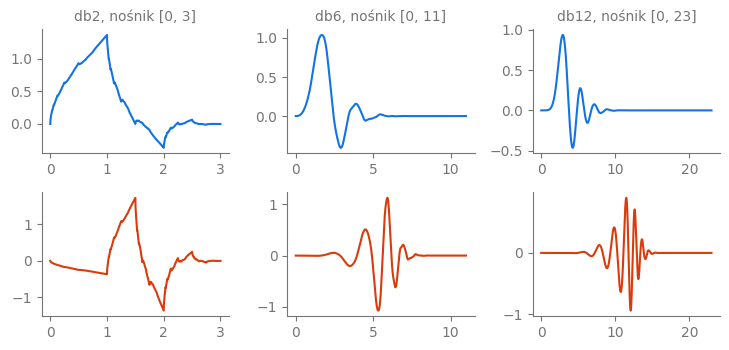

In [10]:
fig, axs = plt.subplots(2, 3, figsize=(7.4, 3.6))
for kol, N in enumerate((2, 6, 12)):
    phi, psi, x = pywt.Wavelet(f"db{N}").wavefun(level=10)
    axs[0, kol].plot(x, phi, color=NIEBIESKI); axs[1, kol].plot(x, psi, color=RDZAWY)
    axs[0, kol].set_title(f"db{N}, nośnik [0, {2*N - 1}]")
    zmiany = np.sum(np.diff(np.sign(psi[np.abs(psi) > 0.02*np.abs(psi).max()])) != 0)
    print(f"db{N}: długość nośnika {x[-1]:.0f}, przejść falki przez zero: {zmiany}")
plt.tight_layout(); plt.show()

### Ćwiczenie 9.3
Sprawdź, że symlet sym2 ma ten sam moduł charakterystyki częstotliwościowej co falka db2, a sym8 ten sam co db8.

### Rozwiązanie 9.3

In [11]:
omega = np.linspace(0, np.pi, 257)
def modul(nazwa):
    h = np.array(pywt.Wavelet(nazwa).rec_lo)
    return np.abs(np.exp(-1j*np.outer(omega, np.arange(len(h)))) @ h)
for N in (2, 3, 8):
    a, b = pywt.Wavelet(f"db{N}"), pywt.Wavelet(f"sym{N}")
    te_same = (np.allclose(a.rec_lo, b.rec_lo)
               or np.allclose(a.rec_lo, b.rec_lo[::-1]))
    print(f"N = {N}: ten sam moduł: {np.allclose(modul(f'db{N}'), modul(f'sym{N}'))},"
          f" te same współczynniki (z dokładnością do odbicia): {te_same}")

N = 2: ten sam moduł: True, te same współczynniki (z dokładnością do odbicia): True
N = 3: ten sam moduł: True, te same współczynniki (z dokładnością do odbicia): True
N = 8: ten sam moduł: True, te same współczynniki (z dokładnością do odbicia): False


### Ćwiczenie 9.4
Porównaj nieliniowość fazy filtrów db8 i sym8: wyznacz opóźnienie grupowe obu filtrów w paśmie przepustowym.

### Rozwiązanie 9.4

db8: opóźnienie od 1.76 do 4.34 próbki, rozrzut 2.58
sym8: opóźnienie od 7.84 do 8.48 próbki, rozrzut 0.64


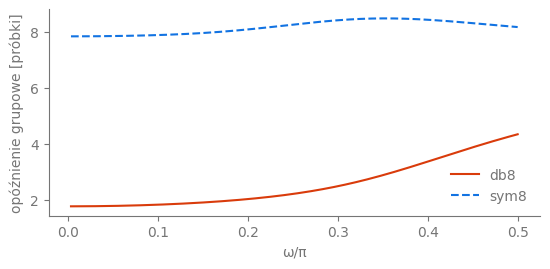

In [12]:
from scipy.signal import group_delay
fig, ax = plt.subplots(figsize=(5.6, 2.8))
for nazwa, kol, ls in (("db8", RDZAWY, "-"), ("sym8", NIEBIESKI, "--")):
    w, gd = group_delay((pywt.Wavelet(nazwa).rec_lo, [1.0]), w=np.linspace(0.01, np.pi/2, 200))
    ax.plot(w/np.pi, gd, color=kol, ls=ls, label=nazwa)
    print(f"{nazwa}: opóźnienie od {gd.min():.2f} do {gd.max():.2f} próbki,"
          f" rozrzut {gd.max() - gd.min():.2f}")
ax.set_xlabel("ω/π"); ax.set_ylabel("opóźnienie grupowe [próbki]")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

### Ćwiczenie 9.5
Sprawdź własność (9.12) dla coifletu coif3 i dla falki db6: porównaj współczynniki aproksymacji pierwszego poziomu funkcji sin x z jej próbkami pomnożonymi przez √2.

### Rozwiązanie 9.5

In [13]:
dt = 0.05
t = np.arange(0, 400)*dt
s = np.sin(t)
for nazwa in ("coif3", "db6"):
    w = pywt.Wavelet(nazwa)
    cA = pywt.dwt(s, w, mode="periodization")[0]
    # najlepsze dopasowanie: próbki przesunięte o stałą liczbę próbek
    najlepszy = min(
        (np.abs(cA[20:-20] - np.sqrt(2)*np.sin((2*np.arange(len(cA)) + p)*dt)[20:-20]).max(), p)
        for p in np.arange(-20, 20, 0.5))
    print(f"{nazwa}: największa różnica {najlepszy[0]:.2e} przy przesunięciu {najlepszy[1]} próbki")

coif3: największa różnica 5.97e-11 przy przesunięciu -2.0 próbki
db6: największa różnica 8.30e-03 przy przesunięciu -3.5 próbki


### Ćwiczenie 9.6
Wyznacz transformatę falką bior2.2 sygnału o wartościach całkowitych, mnożąc filtry tak, aby miały współczynniki wymierne. Czy współczynniki transformaty są liczbami wymiernymi o małych mianownikach?

### Rozwiązanie 9.6

In [14]:
w = pywt.Wavelet("bior2.2")
rng = np.random.default_rng(1)
s = rng.integers(0, 256, size=32).astype(float)
cA, cD = pywt.dwt(s, w, mode="periodization")
print("filtr dolnoprzepustowy · √2:", (np.array(w.dec_lo)*np.sqrt(2)).round(6))
print("filtr górnoprzepustowy · √2:", (np.array(w.dec_hi)*np.sqrt(2)).round(6))
print("cA · √2 · 4 całkowite:", np.allclose(cA*np.sqrt(2)*4, np.round(cA*np.sqrt(2)*4)))
print("cD · √2 · 2 całkowite:", np.allclose(cD*np.sqrt(2)*2, np.round(cD*np.sqrt(2)*2)))

filtr dolnoprzepustowy · √2: [ 0.   -0.25  0.5   1.5   0.5  -0.25]
filtr górnoprzepustowy · √2: [-0.   0.5 -1.   0.5 -0.   0. ]
cA · √2 · 4 całkowite: True
cD · √2 · 2 całkowite: True


### Ćwiczenie 9.7
Narysuj część rzeczywistą, urojoną i moduł falki `cmor` dla B = 0,5; 1,5; 4 oraz C = 1. Ile oscylacji mieści się w falce?

### Rozwiązanie 9.7

B = 0.5: oscylacji w obwiedni (poziom 1/e): 1.4
B = 1.5: oscylacji w obwiedni (poziom 1/e): 2.4
B = 4.0: oscylacji w obwiedni (poziom 1/e): 4.0


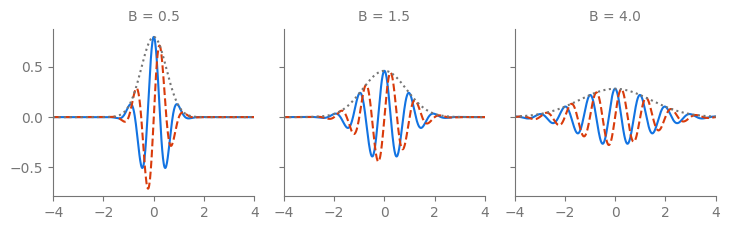

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(7.4, 2.4), sharey=True)
for ax, B in zip(axs, (0.5, 1.5, 4.0)):
    psi, t = pywt.ContinuousWavelet(f"cmor{B}-1.0").wavefun(level=10)
    ax.plot(t, psi.real, color=NIEBIESKI); ax.plot(t, psi.imag, color=RDZAWY, ls="--")
    ax.plot(t, np.abs(psi), color=SZARY, ls=":"); ax.set_xlim(-4, 4)
    ax.set_title(f"B = {B}")
    # szerokość obwiedni na poziomie 1/e maksimum: 2*sqrt(B); okres oscylacji: 1
    print(f"B = {B}: oscylacji w obwiedni (poziom 1/e): {2*np.sqrt(B):.1f}")
plt.tight_layout(); plt.show()

### Ćwiczenie 9.8
Powtórz doświadczenie z kodu 9.7 dla własnego sygnału, na przykład zapisu dźwięku albo danych pomiarowych. Która falka daje najzwięźlejszą reprezentację?

### Rozwiązanie 9.8

In [16]:
# Przykład na danych wbudowanych w PyWavelets: zapis EKG (1024 próbki).
s = pywt.data.ecg().astype(float)
s = s - s.mean()
def ile(s, falka, blad=0.05):
    tab, uklad = pywt.coeffs_to_array(pywt.wavedec(s, falka, mode="periodization"))
    e = np.sort(tab**2)[::-1]
    reszta = np.sqrt(np.clip(e.sum() - np.cumsum(e), 0, None)/e.sum())
    return int(np.argmax(reszta <= blad)) + 1
for falka in ("haar", "db2", "db4", "db8", "sym4", "sym8", "coif3"):
    print(f"{falka:6s} {ile(s, falka):4d} współczynników (błąd 5%)")
# Własny sygnał: wczytaj go np. poleceniem np.loadtxt("dane.txt")
# i przytnij do długości będącej potęgą dwójki.

haar    216 współczynników (błąd 5%)
db2     162 współczynników (błąd 5%)
db4     149 współczynników (błąd 5%)
db8     139 współczynników (błąd 5%)
sym4    142 współczynników (błąd 5%)
sym8    146 współczynników (błąd 5%)
coif3   139 współczynników (błąd 5%)
